# Zela | Redes Neurais Artificiais

**Integrantes**
- Naiara Sousa Soares, RM 574792
- Rafael Medici, RM 576249
- Kayky Cayres Vicente da Silva, RM 575091

## 1. Problema e aplicação

A Zela olha para um problema real do pronto-socorro, pacientes que esperam muito tempo e acabam piorando durante essa espera sem que ninguém perceba. A pulseira mede os sinais vitais de quem está na sala de espera e avisa a equipe quando a leitura chega ao nível de atenção ou crítico.

A rede neural entra antes desse alerta. Ela prevê se o paciente vai chegar ao nível crítico nos próximos 10 minutos, para que a equipe consiga avaliar esse paciente antes da crise. É uma tarefa de **classificação** (sim ou não).

- **Entradas (X)**, 10 features, que são o tempo de espera, os 5 sinais vitais da leitura e 4 features de variação em relação ao normal do próprio paciente.
- **Saída (y)**, `vai_ficar_critico`, que vale 1 se alguma das próximas 5 leituras (10 minutos) for crítica, 0 se não.

Os dados, o alvo e o pré-processamento são os mesmos do notebook de Machine Learning, onde está a análise exploratória completa. Aqui o foco é a MLP.

## 2. Dataset

Para o modelo, partimos de um dataset real e geramos uma versão simulada a partir dele. A base real é a *Five Vital Signs of Normal People*, publicada no Zenodo (https://zenodo.org/records/5549632?preview_file=five+vital+signs+of+normal+people.csv). Ela traz os sinais vitais de 102 pessoas sem doença, medidos por um médico 3 vezes por dia durante 3 dias, ou seja, 9 leituras por pessoa. Os sinais são pressão diastólica, pressão sistólica, frequência cardíaca, saturação de oxigênio e temperatura. O dataset tem 102 linhas, uma por pessoa, e 46 colunas, com o ID e as 9 leituras de cada um dos 5 sinais.

Simulamos porque não existe base pública de pessoas piorando enquanto esperam no pronto-socorro, que é justamente o que a Zela observa. Para cada pessoa, usamos a mediana das 9 leituras como o "normal" dela e, a partir disso, geramos 36 leituras seguidas, uma a cada 2 minutos (0 a 70 min de espera), como se a pulseira estivesse medindo na sala de espera. Cada pessoa recebeu um destes cenários, estável, frequência cardíaca subindo, saturação de oxigênio caindo, combinado ou recuperação. Os sinais mudam aos poucos conforme o cenário, e colocamos um pequeno ruído para não ficar artificialmente liso. A base final tem 3.672 linhas (102 pessoas × 36 leituras) e 12 colunas.

Vale ressaltar que os cenários e o tamanho de cada mudança foram definidos pelo grupo e não seguem um critério clínico. A base real só tem pessoas saudáveis e não informa idade, país nem o aparelho usado. Por isso, o modelo aprende o padrão da nossa simulação. Antes de ser usado em um cenário real, ele precisaria ser treinado com dados reais de pronto-socorro.

Esses dados permitem treinar uma MLP porque são dados tabulares e, depois do pré-processamento, todas as 10 features que entram na rede são numéricas. As colunas de texto ficam de fora. O alvo é definido para cada leitura, sim ou não, o que torna a tarefa uma classificação. São `3.031` leituras de `102` pacientes, o suficiente para uma rede pequena. Além disso, a piora depende da combinação dos sinais, como a frequência cardíaca subindo junto com a saturação caindo, e a MLP consegue aprender essas combinações.

In [1]:
# importando as bibliotecas necessárias para a análise do dataset e visualização em gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# carregando o dataset
df = pd.read_csv('dados/medicoes_pulseira_simuladas.csv')


In [2]:
df.shape # número de linhas e colunas

(3672, 12)

In [3]:
df.info() # informações dos dados

<class 'pandas.DataFrame'>
RangeIndex: 3672 entries, 0 to 3671
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   paciente_id          3672 non-null   int64  
 1   dispositivo_id       3672 non-null   str    
 2   leitura_numero       3672 non-null   int64  
 3   tempo_espera_min     3672 non-null   int64  
 4   frequencia_cardiaca  3672 non-null   int64  
 5   spo2                 3672 non-null   float64
 6   temperatura          3672 non-null   float64
 7   pressao_sistolica    3672 non-null   int64  
 8   pressao_diastolica   3672 non-null   int64  
 9   cenario_simulado     3672 non-null   str    
 10  origem_dado          3672 non-null   str    
 11  fonte_referencia     3672 non-null   str    
dtypes: float64(2), int64(6), str(4)
memory usage: 709.4 KB


In [4]:
df.head() # primeiras 5 linhas

,paciente_id,dispositivo_id,leitura_numero,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,pressao_sistolica,pressao_diastolica,cenario_simulado,origem_dado,fonte_referencia
0,1,ESP32-0001,1,0,74,97.1,35.87,112,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
1,1,ESP32-0001,2,2,73,96.9,35.92,111,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
2,1,ESP32-0001,3,4,75,97.2,35.94,110,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
3,1,ESP32-0001,4,6,74,97.0,35.99,110,64,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
4,1,ESP32-0001,5,8,73,97.3,35.98,109,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...


Podemos ver que o dataset tem 3672 linhas e 12 colunas, cada linha é um momento da espera de um paciente, as colunas trazem a identificação, o tempo de espera, os 5 sinais vitais e o cenário simulado. Todas as linhas e colunas estão preenchidas, nenhum valor é nulo. 8 colunas são numéricas e 4 são de texto.

| Coluna | O que é | Unidade / valores |
|---|---|---|
| paciente_id | identificador da pessoa | 1 a 102 |
| dispositivo_id | identificador da pulseira, uma por pessoa | ESP32-0001 a ESP32-0102 |
| leitura_numero | ordem da leitura daquela pessoa | 1 a 36 |
| tempo_espera_min | minutos desde a chegada na sala de espera | 0 a 70, de 2 em 2 |
| frequencia_cardiaca | batimentos do coração por minuto | bpm |
| spo2 | saturação de oxigênio no sangue | % |
| temperatura | temperatura corporal | °C |
| pressao_sistolica | pressão arterial máxima | mmHg |
| pressao_diastolica | pressão arterial mínima | mmHg |
| cenario_simulado | cenário atribuído à pessoa na simulação | ESTAVEL, FC_ELEVANDO, SPO2_CAINDO, COMBINADO, RECUPERACAO |
| origem_dado | indica que a linha é simulada | sempre "SIMULADO" |
| fonte_referencia | de onde vieram as faixas da simulação | sempre o mesmo texto: simulado, com faixas inspiradas no Zenodo |


In [5]:
df.isna().sum() # verificar valores nulos

paciente_id            0
dispositivo_id         0
leitura_numero         0
tempo_espera_min       0
frequencia_cardiaca    0
spo2                   0
temperatura            0
pressao_sistolica      0
pressao_diastolica     0
cenario_simulado       0
origem_dado            0
fonte_referencia       0
dtype: int64

In [6]:
df.duplicated().sum() # verificar duplicatas

np.int64(0)

Analisamos que não há nenhum dado faltante, assim como vimos antes, e nem dado duplicado. Isso já era esperado, porque a base foi gerada artificialmente.

In [7]:
# regra de crítico, a mesma do monitor em Python
df = df.sort_values(['paciente_id', 'tempo_espera_min'])
df['critico'] = ((df['frequencia_cardiaca'] >= 130) | (df['spo2'] < 90)).astype(int)

# alvo: alguma das próximas 5 leituras (10 min) do mesmo paciente é crítica?
proximas = [df.groupby('paciente_id')['critico'].shift(-k) for k in range(1, 6)]
df['vai_ficar_critico'] = pd.concat(proximas, axis=1).max(axis=1)

df[['paciente_id', 'tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'critico', 'vai_ficar_critico']].head(40)

,paciente_id,tempo_espera_min,frequencia_cardiaca,spo2,critico,vai_ficar_critico
0,1,0,74,97.1,0,0.0
1,1,2,73,96.9,0,0.0
2,1,4,75,97.2,0,0.0
3,1,6,74,97.0,0,0.0
4,1,8,73,97.3,0,0.0
5,1,10,77,96.9,0,0.0
6,1,12,74,97.5,0,0.0
7,1,14,76,97.2,0,0.0
8,1,16,76,96.8,0,0.0
9,1,18,77,97.9,0,0.0


Leituras para o modelo: 3031
vai_ficar_critico
0.0    0.91
1.0    0.09
Name: proportion, dtype: float64


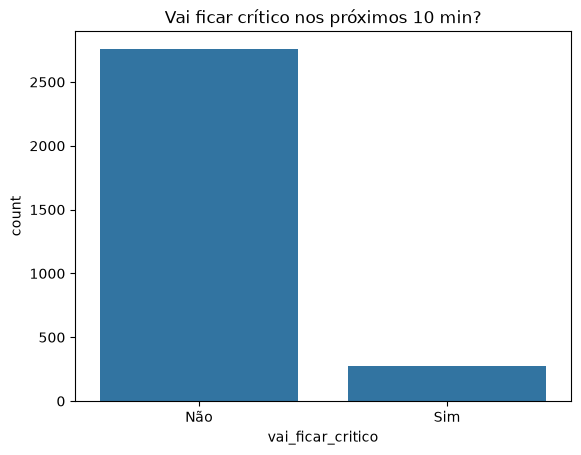

In [8]:
# o modelo só faz sentido para quem ainda NÃO está crítico e tem leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()]

print('Leituras para o modelo:', len(base))
print(base['vai_ficar_critico'].value_counts(normalize=True).round(3))

sns.countplot(data=base, x='vai_ficar_critico')
plt.title('Vai ficar crítico nos próximos 10 min?')
plt.xticks([0, 1], ['Não', 'Sim'])
plt.show()

O alvo é `vai_ficar_critico`, o modelo tenta prever se, nos próximos 10 minutos, o paciente vai chegar ao nível crítico. Se só classificássemos o estado atual, seria uma detecção, e isso a regra da pulseira já faz. Como a base real não tem horário nem pacientes piorando, criamos esse target experimental a partir dos cenários simulados, usando só as informações disponíveis até o momento da leitura.

As leituras que já são críticas saem da base, porque a pulseira já captou esse estado e não há o que prever. A última leitura de cada paciente também sai, porque não tem leituras futuras para dizer se ele ficou crítico.

A base é desbalanceada, 91% das leituras são "não" e só 9% são "sim". Isso acontece porque, mesmo nos cenários de piora, só as leituras dos 10 minutos antes de virar crítico entram como "sim". Por isso a acurácia engana, um modelo que sempre respondesse "não" acertaria 91% sem servir para nada. Vamos olhar principalmente o recall e a precisão.

# 3. Preparação dos dados

**Valores estranhos**

Na base original havia alguns dados inconsistentes, como saturação de oxigênio acima de 100% (até 102%) e temperatura muito baixa (até 33,1 °C). Não sabemos o motivo, porque a base original não informa como as medições foram feitas. Na nossa base, a saturação acima de 100% não aparece, porque a simulação limita a SpO2 em 100%. A temperatura baixa continua, com 85 leituras abaixo de 35 °C, de 8 pacientes. Uma hipótese é que a temperatura tenha sido medida na pele ou no pulso, que fica abaixo da temperatura interna do corpo. Decidimos manter a temperatura, porque ela não entra na regra de crítico.

**Colunas que saem do modelo**

- `leitura_numero` é a mesma informação do `tempo_espera_min`. Não precisamos dessa redundância.
- `paciente_id` e `dispositivo_id` são identificadores e não dizem nada sobre o estado do paciente. O `paciente_id` só fica guardado para separar treino e teste por paciente.
- `origem_dado` e `fonte_referencia` têm o mesmo valor em todas as linhas, então não ajudam o modelo.
- `cenario_simulado` entrega a resposta, porque diz se o paciente vai piorar, e a pulseira real não teria essa informação. Usar essa coluna seria data leakage.

In [9]:
# features de variação, comparando cada leitura com o normal da própria pessoa
paciente = df.groupby('paciente_id')

df['fc_variacao'] = df['frequencia_cardiaca'] - paciente['frequencia_cardiaca'].transform('first')
df['spo2_variacao'] = df['spo2'] - paciente['spo2'].transform('first')

# maior variação até agora, guarda a pior piora, mesmo que o paciente melhore depois
df['fc_maior_subida'] = df.groupby('paciente_id')['fc_variacao'].cummax()
df['spo2_maior_queda'] = df.groupby('paciente_id')['spo2_variacao'].cummin()

df[df['paciente_id'] == 3][['tempo_espera_min', 'frequencia_cardiaca', 'fc_variacao', 'fc_maior_subida',
                            'spo2', 'spo2_variacao', 'spo2_maior_queda']].iloc[::5]

,tempo_espera_min,frequencia_cardiaca,fc_variacao,fc_maior_subida,spo2,spo2_variacao,spo2_maior_queda
72,0,90,0,0,96.7,0.0,0.0
77,10,89,-1,0,95.6,-1.1,-1.1
82,20,89,-1,2,94.5,-2.2,-2.4
87,30,92,2,2,94.0,-2.7,-2.7
92,40,98,8,8,91.4,-5.3,-5.3
97,50,99,9,12,89.9,-6.8,-6.8
102,60,102,12,12,90.3,-6.4,-8.1
107,70,106,16,16,88.0,-8.7,-8.9


As features de variação comparam cada leitura com a primeira leitura da própria pessoa, que serve como referência do seu normal. Assim o modelo faz uma comparação mais justa, uma FC de 100 pode ser normal para uma pessoa e uma piora para outra. A maior variação até agora guarda a pior piora que a pessoa já teve na espera, para o modelo não esquecer quem piorou e depois melhorou, porque essa pessoa ainda pode voltar a piorar.

In [10]:
# base do modelo, só leituras ainda não críticas e com leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()].copy()

# entradas (X) e saída (y), as colunas descartadas na EDA ficam de fora
features = ['tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'temperatura',
            'pressao_sistolica', 'pressao_diastolica',
            'fc_variacao', 'spo2_variacao', 'fc_maior_subida', 'spo2_maior_queda']

X = base[features]
y = base['vai_ficar_critico'].astype(int)
print('X:', X.shape, '| y:', y.shape)

X: (3031, 10) | y: (3031,)


In [11]:
from sklearn.model_selection import train_test_split

# holdout por paciente, todas as leituras de um paciente ficam só no treino ou só no teste
pacientes = base.groupby('paciente_id')['vai_ficar_critico'].max()
treino_ids, teste_ids = train_test_split(pacientes.index, test_size=0.2,
                                         stratify=pacientes, random_state=42)

no_treino = base['paciente_id'].isin(treino_ids)
X_train, X_test = X[no_treino], X[~no_treino]
y_train, y_test = y[no_treino], y[~no_treino]

print('Pacientes  treino:', len(treino_ids), '| teste:', len(teste_ids))
print('Leituras   treino:', len(X_train), '| teste:', len(X_test))
print('% que vai ficar crítico  treino:', round(y_train.mean(), 3), '| teste:', round(y_test.mean(), 3))
print('Pacientes nos dois conjuntos:', len(set(treino_ids) & set(teste_ids)))

Pacientes  treino: 81 | teste: 21
Leituras   treino: 2415 | teste: 616
% que vai ficar crítico  treino: 0.091 | teste: 0.086
Pacientes nos dois conjuntos: 0


O split é feito por paciente, e não por leitura. Se as leituras do mesmo paciente caíssem no treino e no teste, o modelo iria reconhecer esse paciente e decorar os dados dele, e o resultado no teste sairia melhor do que seria com um paciente novo.

In [12]:
from sklearn.preprocessing import StandardScaler

# padronização, média 0 e desvio 1, o fit usa SÓ o treino para o teste não vazar
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

pd.DataFrame(X_train_esc, columns=features).describe().round(2).loc[['mean', 'std']]

,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,pressao_sistolica,pressao_diastolica,fc_variacao,spo2_variacao,fc_maior_subida,spo2_maior_queda
mean,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


O StandardScaler deixa todas as features na mesma escala (média 0 e desvio 1). O modelo só enxerga números, por exemplo uma variação de 5 na saturação de oxigênio é grave, enquanto 5 a mais na pressão sistólica quase não muda nada, mas sem a padronização a feature com valores maiores acabaria pesando mais. O fit, que calcula a média e o desvio, é feito só com o treino, e o teste é transformado com esses mesmos valores. Se o teste entrasse no cálculo, seria como estudar para a prova com as respostas já prontas.

O StandardScaler é ainda mais importante numa MLP, porque a rede começa com pesos aleatórios e vai ajustando os pesos e o viés aos poucos, a cada iteração. Se uma feature tem valores muito maiores que outra, esses ajustes ficam desequilibrados, e a rede demora muito para aprender ou nem chega a convergir. Com tudo na mesma escala, o treino fica mais estável.

# 4. A MLP

Escolhemos uma rede com 10 entradas, que são as features, uma camada oculta com 8 neurônios e uma saída. Essa saída é a chance de o paciente ficar crítico, de 0 a 100%. É uma rede pequena porque a base tem poucas leituras e só 10 features.

Cada neurônio multiplica as entradas por pesos, soma o viés e passa o resultado pela função de ativação. A ativação é a `relu`, que zera o resultado quando ele é negativo, e é ela que deixa a rede aprender combinações não lineares entre os sinais. O `adam` é o otimizador que ajusta os pesos durante o treino. Os dois são o padrão do scikit-learn e não alteramos nenhum.

O fluxo começa com a leitura da pulseira, que passa pelo StandardScaler com a média e o desvio padrão do treino. Depois entra na MLP, que devolve a chance de o paciente ficar crítico, e avisa se essa chance passar do limiar.

In [13]:
from sklearn.neural_network import MLPClassifier

# 1 camada oculta com 8 neurônios, random_state fixo para o resultado ser reproduzível
mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
mlp.fit(X_train_esc, y_train)  # só o treino, o teste fica guardado para a avaliação

print('Camadas ocultas:', mlp.hidden_layer_sizes)
print('Função de ativação:', mlp.activation, '| otimizador:', mlp.solver)
print('Iterações até parar:', mlp.n_iter_, 'de', mlp.max_iter)
print('Perda (loss) final no treino:', round(mlp.loss_, 3))

Camadas ocultas: (8,)
Função de ativação: relu | otimizador: adam
Iterações até parar: 683 de 1000
Perda (loss) final no treino: 0.064


# 5. Treinamento

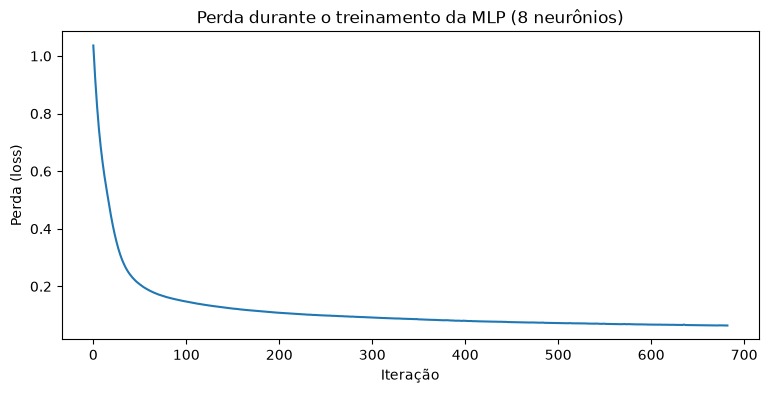

In [14]:
# curva da perda (loss), quanto a rede ainda erra no treino a cada iteração
plt.figure(figsize=(9, 4))
plt.plot(mlp.loss_curve_)
plt.title('Perda durante o treinamento da MLP (8 neurônios)')
plt.xlabel('Iteração')
plt.ylabel('Perda (loss)')
plt.show()

Analisando a curva da perda, podemos ver que ela cai rapidamente nas primeiras 50 iterações, de `1,04` para `0,21`. Depois, a queda fica mais lenta e, a partir da iteração 200, quase não muda. A rede parou sozinha na iteração `683`, antes do limite de `1000`, porque a perda deixou de melhorar. Vale ressaltar que uma perda baixa no treino não garante acerto em pacientes que a rede nunca viu, isso só a avaliação no teste mostra.

# 6. Ajuste simples

In [15]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# validação cruzada dentro do treino, separando por paciente, o teste não entra na escolha
grupos = base.loc[no_treino, 'paciente_id']
validacao = GroupKFold(n_splits=5)

def chances_validacao(neuronios):
    # para cada parte da validação: scaler ajustado só nas outras partes, MLP treinada e chance prevista
    chances = pd.Series(0.0, index=y_train.index)
    for idx_treino, idx_valid in validacao.split(X_train, y_train, grupos):
        esc = StandardScaler().fit(X_train.iloc[idx_treino])
        rede = MLPClassifier(hidden_layer_sizes=neuronios, max_iter=1000, random_state=42)
        rede.fit(esc.transform(X_train.iloc[idx_treino]), y_train.iloc[idx_treino])
        chances.iloc[idx_valid] = rede.predict_proba(esc.transform(X_train.iloc[idx_valid]))[:, 1]
    return chances

def metricas(y_real, y_prev):
    return {'acurácia': accuracy_score(y_real, y_prev), 'recall': recall_score(y_real, y_prev),
            'precisão': precision_score(y_real, y_prev), 'F1': f1_score(y_real, y_prev)}

# muda só um elemento, o número de neurônios. Mesma divisão, mesmo scaler, mesmas métricas
linhas = {}
for neuronios in [(32,), (8,)]:
    chances = chances_validacao(neuronios)
    rede = MLPClassifier(hidden_layer_sizes=neuronios, max_iter=1000, random_state=42).fit(X_train_esc, y_train)
    validacao_m = metricas(y_train, (chances >= 0.5).astype(int))
    teste_m = metricas(y_test, rede.predict(X_test_esc))
    linhas[f'{neuronios[0]} neurônios'] = {
        'loss treino': rede.loss_, 'recall validação': validacao_m['recall'], 'precisão validação': validacao_m['precisão'],
        'recall teste': teste_m['recall'], 'precisão teste': teste_m['precisão'], 'F1 teste': teste_m['F1']}

comparacao = pd.DataFrame(linhas).T.round(3)
comparacao

,loss treino,recall validação,precisão validação,recall teste,precisão teste,F1 teste
32 neurônios,0.040,0.582,0.549,0.679,0.706,0.692
8 neurônios,0.064,0.673,0.661,0.792,0.750,0.771


Testamos uma segunda rede para fazer a comparação, mudando apenas o número de neurônios, 32 no lugar de 8. A divisão dos dados, o StandardScaler e as métricas são os mesmos. A rede com 32 neurônios acerta mais no treino (perda `0,040` contra `0,064`), mas na validação acerta menos, com recall de `0,58` contra `0,67` e precisão de `0,55` contra `0,66`. Isso quer dizer que ela decorou os pacientes de treino, ou seja, houve overfitting. Por isso escolhemos a rede de 8 neurônios, que ganha em recall e em precisão na validação. A escolha foi feita pela validação cruzada, e o teste só confirma, com a rede de 8 neurônios melhor também nele.

In [16]:
# a MLPClassifier não tem class_weight, então tratamos o desbalanceamento pelo limiar:
# a rede avisa quando a chance passa do limiar, e um limiar menor avisa mais pacientes
chances_8 = chances_validacao((8,))
limiares = pd.DataFrame({limiar: metricas(y_train, (chances_8 >= limiar).astype(int))
                         for limiar in [0.5, 0.3, 0.2, 0.1]}).T.round(3)
limiares.index.name = 'limiar'
limiares

,acurácia,recall,precisão,F1
limiar,,,,
0.5,0.939,0.673,0.661,0.667
0.3,0.936,0.795,0.614,0.693
0.2,0.927,0.832,0.567,0.674
0.1,0.909,0.886,0.500,0.639


Como a `MLPClassifier` não tem `class_weight`, que foi o que usamos no ML para tratar o desbalanceamento, ajustamos o limiar. A rede dá uma chance de 0 a 100% de o paciente ficar crítico, e o aviso acontece quando essa chance passa do limiar. Como só 9% das leituras são "sim", a rede raramente passa de 50%, e com o limiar padrão de `0,5` ela deixa passar muitos pacientes. Quanto menor o limiar, mais pacientes ela avisa, mas também dá mais alarmes falsos. Escolhemos o limiar de `0,1`, porque, assim como no ML, a prioridade é não deixar passar quem vai piorar. Na validação, ele tem o maior recall (`0,89`) com precisão de `0,50`, próximo da Regressão Logística do ML (`0,91` e `0,47`).

# 7. Avaliação

,"MLP (8 neurônios, limiar 0,1)",Regressão Logística (ML)
acurácia,0.945,0.894
recall,0.906,0.830
precisão,0.623,0.440
F1,0.738,0.575


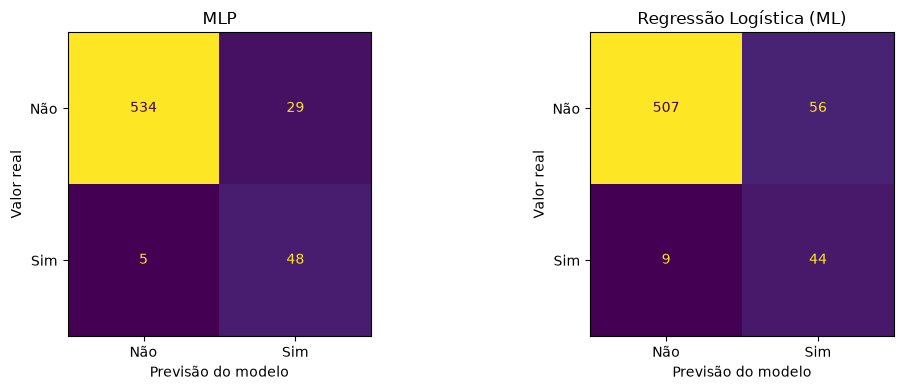

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

LIMIAR = 0.1  # escolhido na validação cruzada acima
prev_mlp = (mlp.predict_proba(X_test_esc)[:, 1] >= LIMIAR).astype(int)

# a Regressão Logística do notebook de ML, mesma divisão e mesmo scaler, só como referência
logistica = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_esc, y_train)
prev_logistica = logistica.predict(X_test_esc)

resultados = pd.DataFrame({'MLP (8 neurônios, limiar 0,1)': metricas(y_test, prev_mlp),
                           'Regressão Logística (ML)': metricas(y_test, prev_logistica)}).round(3)
display(resultados)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, prev) in zip(axes, [('MLP', prev_mlp), ('Regressão Logística (ML)', prev_logistica)]):
    ConfusionMatrixDisplay.from_predictions(y_test, prev, display_labels=['Não', 'Sim'], ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel('Previsão do modelo')
    ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()

No teste, a MLP avisou `48` dos `53` casos que iam ficar críticos e deixou passar só `5`, um recall de `0,91`. Na precisão, de cada 10 avisos, uns 6 eram casos reais (`0,62`). Foram `29` alarmes falsos, metade dos `56` da Regressão Logística. A acurácia engana aqui, porque um modelo que sempre respondesse "não" já teria uns `91%` no teste, por isso avaliamos principalmente pelo recall e pela precisão.

Comparando com a Regressão Logística de ML, no teste a MLP saiu na frente nas duas métricas (recall `0,91` contra `0,83` e precisão `0,62` contra `0,44`). Na validação, os dois ficaram bem parecidos, com a logística um pouco à frente no recall e a MLP na precisão. Como o teste tem só 21 pacientes, parte dessa diferença pode ser sorte do sorteio.

In [18]:
# onde a MLP errou: os casos que iam ficar críticos e não receberam aviso (falsos negativos)
teste = base.loc[~no_treino].copy()
teste['chance_mlp'] = mlp.predict_proba(X_test_esc)[:, 1].round(3)
erros = teste[(prev_mlp == 0) & (y_test == 1)]
erros[['paciente_id', 'cenario_simulado', 'tempo_espera_min', 'frequencia_cardiaca', 'spo2',
       'fc_variacao', 'spo2_variacao', 'chance_mlp']]

,paciente_id,cenario_simulado,tempo_espera_min,frequencia_cardiaca,spo2,fc_variacao,spo2_variacao,chance_mlp
511,15,RECUPERACAO,14,110,96.5,10,-1.7,0.000
512,15,RECUPERACAO,16,116,95.3,16,-2.9,0.008
1202,34,COMBINADO,28,98,93.4,20,-5.0,0.035
2466,69,COMBINADO,36,111,93.4,24,-5.4,0.012
2467,69,COMBINADO,38,114,93.4,27,-5.4,0.026


In [19]:
# alarmes falsos por cenário
teste.loc[(prev_mlp == 1) & (y_test == 0), 'cenario_simulado'].value_counts()

cenario_simulado
RECUPERACAO    11
COMBINADO      10
SPO2_CAINDO     8
Name: count, dtype: int64

A rede deixou passar `2` leituras do paciente 15, `1` do paciente 34 e `2` do paciente 69. Todas estavam a `8` ou `10` minutos da crise, ou seja, na ponta mais distante da janela de 10 minutos. Nesse ponto os sinais ainda tinham mudado pouco, e a chance que a rede deu ficou abaixo de `4%`. Esses três pacientes receberam o aviso depois, antes de ficarem críticos, então nenhum paciente passou sem aviso.

Dos `29` alarmes falsos, nenhum foi em paciente estável. `20` foram em pacientes que ficaram críticos mais tarde, depois da janela de 10 minutos, `5` em pacientes da recuperação que pioraram mas nunca chegaram ao crítico, e `4` em leituras de quem já tinha passado pelo crítico e estava melhorando. Ou seja, quase todos os alarmes falsos foram em pacientes que de fato estavam piorando, e boa parte do "falso" vem do corte rígido do nosso alvo.

Algumas limitações são que os dados foram simulados pelo grupo, então a rede aprende o padrão dessa simulação. Temos só `21` pacientes no teste, e a regra de crítico ainda não tem fonte clínica.

# 8. Demonstração

In [20]:
# simulação, as leituras de um paciente do teste chegam uma a uma, como na pulseira
def estado_pulseira(fc, spo2):
    # mesma regra do monitor em Python
    if fc >= 130 or spo2 < 90:
        return 'CRÍTICO'
    elif fc >= 110 or fc < 50 or spo2 < 95:
        return 'ATENÇÃO'
    return 'NORMAL'

def acompanhar(paciente_id):
    leituras = df[df['paciente_id'] == paciente_id]
    for _, leitura in leituras.iterrows():
        estado = estado_pulseira(leitura['frequencia_cardiaca'], leitura['spo2'])
        chance = mlp.predict_proba(scaler.transform(leitura[features].to_frame().T))[0, 1]
        aviso = '<< AVISO DA MLP' if estado != 'CRÍTICO' and chance >= LIMIAR else ''
        # valor real, se alguma das próximas 5 leituras (10 min) foi de fato crítica
        real = '' if estado == 'CRÍTICO' else ('sim' if leitura['vai_ficar_critico'] == 1 else 'não')
        print(f"{leitura['tempo_espera_min']:>3.0f} min | FC {leitura['frequencia_cardiaca']:>3.0f} | "
              f"SpO2 {leitura['spo2']:>5.1f} | pulseira: {estado:<8} | chance de ficar crítico: {chance:>4.0%} | "
              f"real: {real:<3} {aviso}")
        if estado == 'CRÍTICO':
            break  # a partir daqui a regra da pulseira já está alertando

acompanhar(4)  # paciente do teste, a rede nunca viu as leituras dele

  0 min | FC  86 | SpO2  95.4 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  2 min | FC  87 | SpO2  95.9 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  4 min | FC  87 | SpO2  95.0 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  6 min | FC  86 | SpO2  95.3 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  8 min | FC  93 | SpO2  95.5 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 10 min | FC  93 | SpO2  95.8 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 12 min | FC  94 | SpO2  95.3 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 14 min | FC  92 | SpO2  94.8 | pulseira: ATENÇÃO  | chance de ficar crítico:   0% | real: não 
 16 min | FC  95 | SpO2  94.4 | pulseira: ATENÇÃO  | chance de ficar crítico:   0% | real: não 
 18 min | FC  96 | SpO2  94.1 | pulseira: ATENÇÃO  | chance de ficar crítico:   1% | real: não 
 20 min | FC  96 | SpO2  94.2 | pulseira

O paciente 4 entrou em estado de atenção aos `14` minutos. A MLP deu o primeiro aviso aos `24` minutos, com `30%` de chance, e ele ficou crítico aos `36` minutos, ou seja, `12` minutos de antecedência. O aviso tem valor porque a equipe veria a atenção desde os 14 minutos, mas muitos pacientes passam pela atenção e nunca ficam críticos. O aviso chega quando o paciente está com tendência a ficar crítico, e assim a equipe pode reavaliar esse paciente antes da crise.

Comparando com a Regressão Logística de ML, ela avisou o mesmo paciente aos `16` minutos, `20` minutos de antecedência. A MLP avisa um pouco mais tarde, mas com menos alarmes falsos. Vale ressaltar que as leituras chegam uma a uma no notebook, como chegariam da pulseira. A integração com a pulseira em tempo real não foi implementada e fica como melhoria futura.

In [21]:
# quando a MLP avisou se o paciente iria ficar crítico e com quanto tempo de antecedência
linhas = []
for pid in teste_ids:
    leituras = df[df['paciente_id'] == pid]
    chance = mlp.predict_proba(scaler.transform(leituras[features]))[:, 1]
    aviso = (chance >= LIMIAR) & (leituras['critico'] == 0)
    critico = leituras['critico'] == 1
    t_critico = leituras.loc[critico, 'tempo_espera_min'].min() if critico.any() else None
    antes = aviso & ((leituras['tempo_espera_min'] < t_critico) if t_critico is not None else True)
    t_aviso = leituras.loc[antes, 'tempo_espera_min'].min() if antes.any() else None
    linhas.append({'paciente_id': pid, 'cenário': leituras['cenario_simulado'].iloc[0],
                   'ficou crítico (min)': t_critico, 'primeiro aviso (min)': t_aviso})

acompanhamento = pd.DataFrame(linhas).sort_values('paciente_id')
acompanhamento['antecedência (min)'] = acompanhamento['ficou crítico (min)'] - acompanhamento['primeiro aviso (min)']

criticos = acompanhamento.dropna(subset=['ficou crítico (min)'])
print('Pacientes do teste que ficaram críticos:', len(criticos))
print('Avisados antes pelo modelo:', criticos['antecedência (min)'].notna().sum())
print('Antecedência mediana:', criticos['antecedência (min)'].median(), 'min')
acompanhamento

Pacientes do teste que ficaram críticos: 10
Avisados antes pelo modelo: 10
Antecedência mediana: 13.0 min


,paciente_id,cenário,ficou crítico (min),primeiro aviso (min),antecedência (min)
13,4,COMBINADO,36.0,24.0,12.0
17,14,COMBINADO,34.0,24.0,10.0
19,15,RECUPERACAO,24.0,18.0,6.0
6,16,ESTAVEL,NaN,NaN,NaN
10,21,ESTAVEL,NaN,NaN,NaN
4,28,SPO2_CAINDO,64.0,38.0,26.0
15,30,RECUPERACAO,NaN,30.0,NaN
20,34,COMBINADO,38.0,30.0,8.0
8,37,FC_ELEVANDO,NaN,NaN,NaN
2,39,COMBINADO,48.0,30.0,18.0


Dos `21` pacientes do teste, `10` ficaram críticos, e a MLP avisou todos os `10` antes da crise, com antecedência mediana de `13` minutos, variando de `6` a `26` minutos.

Dos `11` pacientes que nunca ficaram críticos, nenhum dos `3` estáveis e nenhum dos `5` com frequência cardíaca subindo recebeu aviso. Só um recebeu, o paciente 30, do cenário de recuperação, que piorou sem chegar ao estado crítico.

Comparando com o ML, a Regressão Logística avisou `9` dos `10`, com antecedência mediana de `18` minutos. Então a MLP não deixou ninguém passar, mas avisa um pouco mais tarde que a logística. Isso beneficia o paciente que ia piorar na espera, que pode ser avaliado antes da crise, e ajuda a equipe a saber quem precisa de atenção primeiro, sem gerar aviso para quem está estável.

# 9. Conclusão

A nossa solução olha para um problema real do pronto-socorro, pacientes que esperam muito tempo e acabam piorando durante essa espera sem que ninguém perceba. O objetivo da rede neural é prever se a leitura da pulseira vai ficar crítica nos próximos 10 minutos, para que a equipe consiga agir antes da crise.

A rede escolhida foi uma MLP com uma camada oculta de 8 neurônios, porque a rede de 32 neurônios decorou o treino e foi pior na validação. Como a `MLPClassifier` não tem `class_weight`, baixamos o limiar do aviso para `0,1`, porque priorizamos o recall e não queremos que pacientes que vão piorar passem sem aviso, mesmo que isso traga mais alarmes falsos.

No teste, a rede teve recall de `0,91` e precisão de `0,62`. Na aplicação prática, os `10` pacientes do teste que ficaram críticos foram avisados antes, com antecedência mediana de `13` minutos, e nenhum paciente estável recebeu aviso. Comparando com a Regressão Logística do ML, a MLP avisou mais pacientes e deu menos alarmes falsos, mas avisa um pouco mais tarde. É um resultado bom para uma primeira versão, mas vem de poucos pacientes de teste.

A maior limitação da nossa solução é que o alvo é experimental e os dados foram simulados por nós. A rede aprende o padrão da simulação, e para uso real seriam necessários dados de pacientes de pronto-socorro. A regra de crítico também ainda não tem fonte clínica.

Sobre privacidade e segurança, os dados deste notebook são simulados e não têm nenhuma informação pessoal, cada paciente aparece só por um número. Em uso real seriam dados de saúde, que a LGPD (Lei 13.709/2018) trata como dado pessoal sensível, então a pulseira precisaria identificar o paciente só por um código, recusar leituras impossíveis e proteger os arquivos contra alteração, como mostramos na parte de Cyber Security. O aviso da rede também não é um diagnóstico, ele só ajuda a equipe a decidir quem olhar primeiro, e a decisão continua sendo da equipe. Para o paciente, a pulseira não exige nenhuma ação, ele não precisa usar aplicativo nem saber ler para ser monitorado.

Como melhorias futuras, queremos treinar a rede com dados reais, integrar o modelo com a pulseira em tempo real e usar regras de crítico baseadas em fontes clínicas.